In [1]:
import pandas as pd
import numpy as np
import polars as pl
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
from data_processing import import_data

In [3]:
lf = import_data()

# General statistics

In [4]:
for col in ['delta_days', 'sales_net', 'quantity']:

    print('_________________________________________')
    print(f"Statistiques pour la colonne {col}:")
    stats = lf.select(
        pl.col(col).count().alias("nb_valides"),
        pl.col(col).null_count().alias("nb_nulls"),
        pl.col(col).mean().alias("moyenne"),
        pl.col(col).std().alias("ecart_type"),
        pl.col(col).min().alias("min"),
        pl.col(col).median().alias("mediane"),
        pl.col(col).max().alias("max"),
    ).collect(engine="streaming")

    print(stats)

_________________________________________
Statistiques pour la colonne delta_days:
shape: (1, 7)
┌────────────┬──────────┬──────────┬────────────┬──────┬─────────┬──────┐
│ nb_valides ┆ nb_nulls ┆ moyenne  ┆ ecart_type ┆ min  ┆ mediane ┆ max  │
│ ---        ┆ ---      ┆ ---      ┆ ---        ┆ ---  ┆ ---     ┆ ---  │
│ u32        ┆ u32      ┆ f64      ┆ f64        ┆ i64  ┆ f64     ┆ i64  │
╞════════════╪══════════╪══════════╪════════════╪══════╪═════════╪══════╡
│ 63319314   ┆ 1        ┆ 5.060313 ┆ 19.921085  ┆ -406 ┆ 0.0     ┆ 1302 │
└────────────┴──────────┴──────────┴────────────┴──────┴─────────┴──────┘
_________________________________________
Statistiques pour la colonne sales_net:
shape: (1, 7)
┌────────────┬──────────┬────────────┬────────────┬───────────┬─────────┬────────────┐
│ nb_valides ┆ nb_nulls ┆ moyenne    ┆ ecart_type ┆ min       ┆ mediane ┆ max        │
│ ---        ┆ ---      ┆ ---        ┆ ---        ┆ ---       ┆ ---     ┆ ---        │
│ u32        ┆ u32      ┆ f6

shape: (5, 6)
┌─────────────────────────────────┬───────────┬──────────┬────────────┬────────────┬────────┐
│ order_channel                   ┆ nb_lignes ┆ ca       ┆ nb_clients ┆ pct_lignes ┆ pct_ca │
│ ---                             ┆ ---       ┆ ---      ┆ ---        ┆ ---        ┆ ---    │
│ str                             ┆ u32       ┆ f64      ┆ u32        ┆ f64        ┆ f64    │
╞═════════════════════════════════╪═══════════╪══════════╪════════════╪════════════╪════════╡
│ at the store                    ┆ 32114196  ┆ 2.4501e9 ┆ 146857     ┆ 50.72      ┆ 26.16  │
│ by phone                        ┆ 25465205  ┆ 6.0301e9 ┆ 135602     ┆ 40.22      ┆ 64.37  │
│ online                          ┆ 5651866   ┆ 8.7102e8 ┆ 21352      ┆ 8.93       ┆ 9.3    │
│ other                           ┆ 58735     ┆ 8.8495e6 ┆ 8811       ┆ 0.09       ┆ 0.09   │
│ during the visit of a sales re… ┆ 29313     ┆ 7.4432e6 ┆ 1203       ┆ 0.05       ┆ 0.08   │
└─────────────────────────────────┴───────────

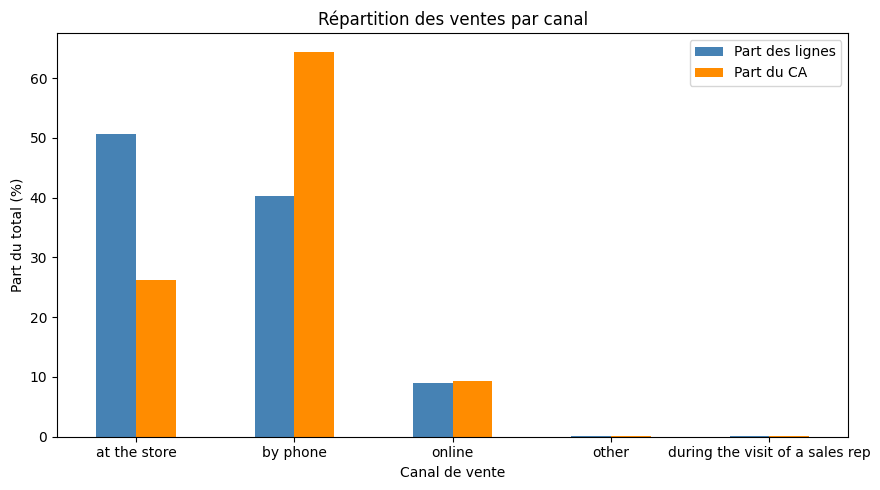

In [5]:
repartition = (
    lf
    .with_columns(
        pl.col("order_channel").fill_null("Non renseigné")
    )
    .group_by("order_channel")
    .agg(
        pl.len().alias("nb_lignes"),
        pl.col("sales_net").sum().alias("ca"),
        pl.col("client_id").drop_nulls().n_unique().alias("nb_clients"),
    )
    .with_columns(
        (100 * pl.col("nb_lignes") / pl.col("nb_lignes").sum())
        .round(2).alias("pct_lignes"),

        (100 * pl.col("ca") / pl.col("ca").sum())
        .round(2).alias("pct_ca"),
    )
    .sort("nb_lignes", descending=True)
    .collect(engine="streaming")
)

print(repartition)

r = repartition.to_pandas().set_index("order_channel")

r[["pct_lignes", "pct_ca"]].plot.bar(
    figsize=(9, 5),
    color=["steelblue", "darkorange"],
    rot=0,
)

plt.title("Répartition des ventes par canal")
plt.xlabel("Canal de vente")
plt.ylabel("Part du total (%)")
plt.legend(["Part des lignes", "Part du CA"])
plt.tight_layout()
plt.show()

# Exploration des habitudes client

In [6]:
quotidien = (
    lf
    .select("client_id", "date_order", "sales_net", "quantity")
    .with_columns(
        pl.col("date_order").dt.date().alias("date")
    )
    .filter(
        pl.col("client_id").is_not_null()
        & pl.col("date").is_not_null()
        & (pl.col("quantity") > 0)
    )
    .group_by(["client_id", "date"])
    .agg(
        pl.col("sales_net").sum().alias("ca_achats"),
        pl.len().alias("nb_lignes"),
    )
)

In [7]:
# Date de référence de l'analyse : fin de l'historique disponible
date_fin = quotidien.select(pl.col("date").max()).collect().item()

intervalles = (
    quotidien
    .sort(["client_id", "date"])
    .with_columns(
        pl.col("date")
        .diff()
        .over("client_id")
        .dt.total_days()
        .alias("intervalle_j")
    )
)

profils = (
    intervalles
    .group_by("client_id")
    .agg(
        pl.col("date").min().alias("premier_achat"),
        pl.col("date").max().alias("dernier_achat"),
        pl.len().alias("nb_jours_achat"),
        pl.col("ca_achats").sum().alias("ca_total"),
        pl.col("intervalle_j").median().alias("intervalle_median_j"),
        pl.col("intervalle_j").mean().alias("intervalle_moyen_j"),
        pl.col("intervalle_j").std().alias("intervalle_std_j"),
        pl.col("intervalle_j").max().alias("intervalle_max_j"),
    )
    .with_columns(
        (pl.lit(date_fin) - pl.col("premier_achat"))
        .dt.total_days().alias("anciennete_j"),

        (pl.lit(date_fin) - pl.col("dernier_achat"))
        .dt.total_days().alias("recence_j"),

        (pl.col("intervalle_std_j") / pl.col("intervalle_moyen_j"))
        .alias("cv_intervalles"),

        (pl.col("ca_total") / pl.col("nb_jours_achat"))
        .alias("ca_par_jour_achat"),
    )
    .with_columns(
        (pl.col("recence_j") / pl.col("intervalle_median_j"))
        .alias("retard_relatif")
    )
    .collect(engine="streaming")
)

print(f"Clients étudiés : {profils.height:,}")

stats = (
    profils
    .select(
        "nb_jours_achat",
        "anciennete_j",
        "recence_j",
        "intervalle_median_j",
        "cv_intervalles",
        "retard_relatif",
        "ca_total",
    )
    .describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.95])
    .with_columns(
        pl.col(pl.Float64).round(2)
    )
)

# Afficher toutes les lignes et colonnes du résumé
with pl.Config(tbl_rows=-1, tbl_cols=-1):
    print(stats)

Clients étudiés : 170,589
shape: (12, 8)
┌────────────┬────────────┬────────────┬───────────┬───────────┬───────────┬───────────┬───────────┐
│ statistic  ┆ nb_jours_a ┆ anciennete ┆ recence_j ┆ intervall ┆ cv_interv ┆ retard_re ┆ ca_total  │
│ ---        ┆ chat       ┆ _j         ┆ ---       ┆ e_median_ ┆ alles     ┆ latif     ┆ ---       │
│ str        ┆ ---        ┆ ---        ┆ f64       ┆ j         ┆ ---       ┆ ---       ┆ f64       │
│            ┆ f64        ┆ f64        ┆           ┆ ---       ┆ f64       ┆ f64       ┆           │
│            ┆            ┆            ┆           ┆ f64       ┆           ┆           ┆           │
╞════════════╪════════════╪════════════╪═══════════╪═══════════╪═══════════╪═══════════╪═══════════╡
│ count      ┆ 170589.0   ┆ 170589.0   ┆ 170589.0  ┆ 149508.0  ┆ 136335.0  ┆ 149508.0  ┆ 170589.0  │
│ null_count ┆ 0.0        ┆ 0.0        ┆ 0.0       ┆ 21081.0   ┆ 34254.0   ┆ 21081.0   ┆ 0.0       │
│ mean       ┆ 46.63      ┆ 581.63     ┆ 152.08   

Clients au total : 170,589
Historique ≥ 90 jours : 164,015
Rythme analysable : 117,824


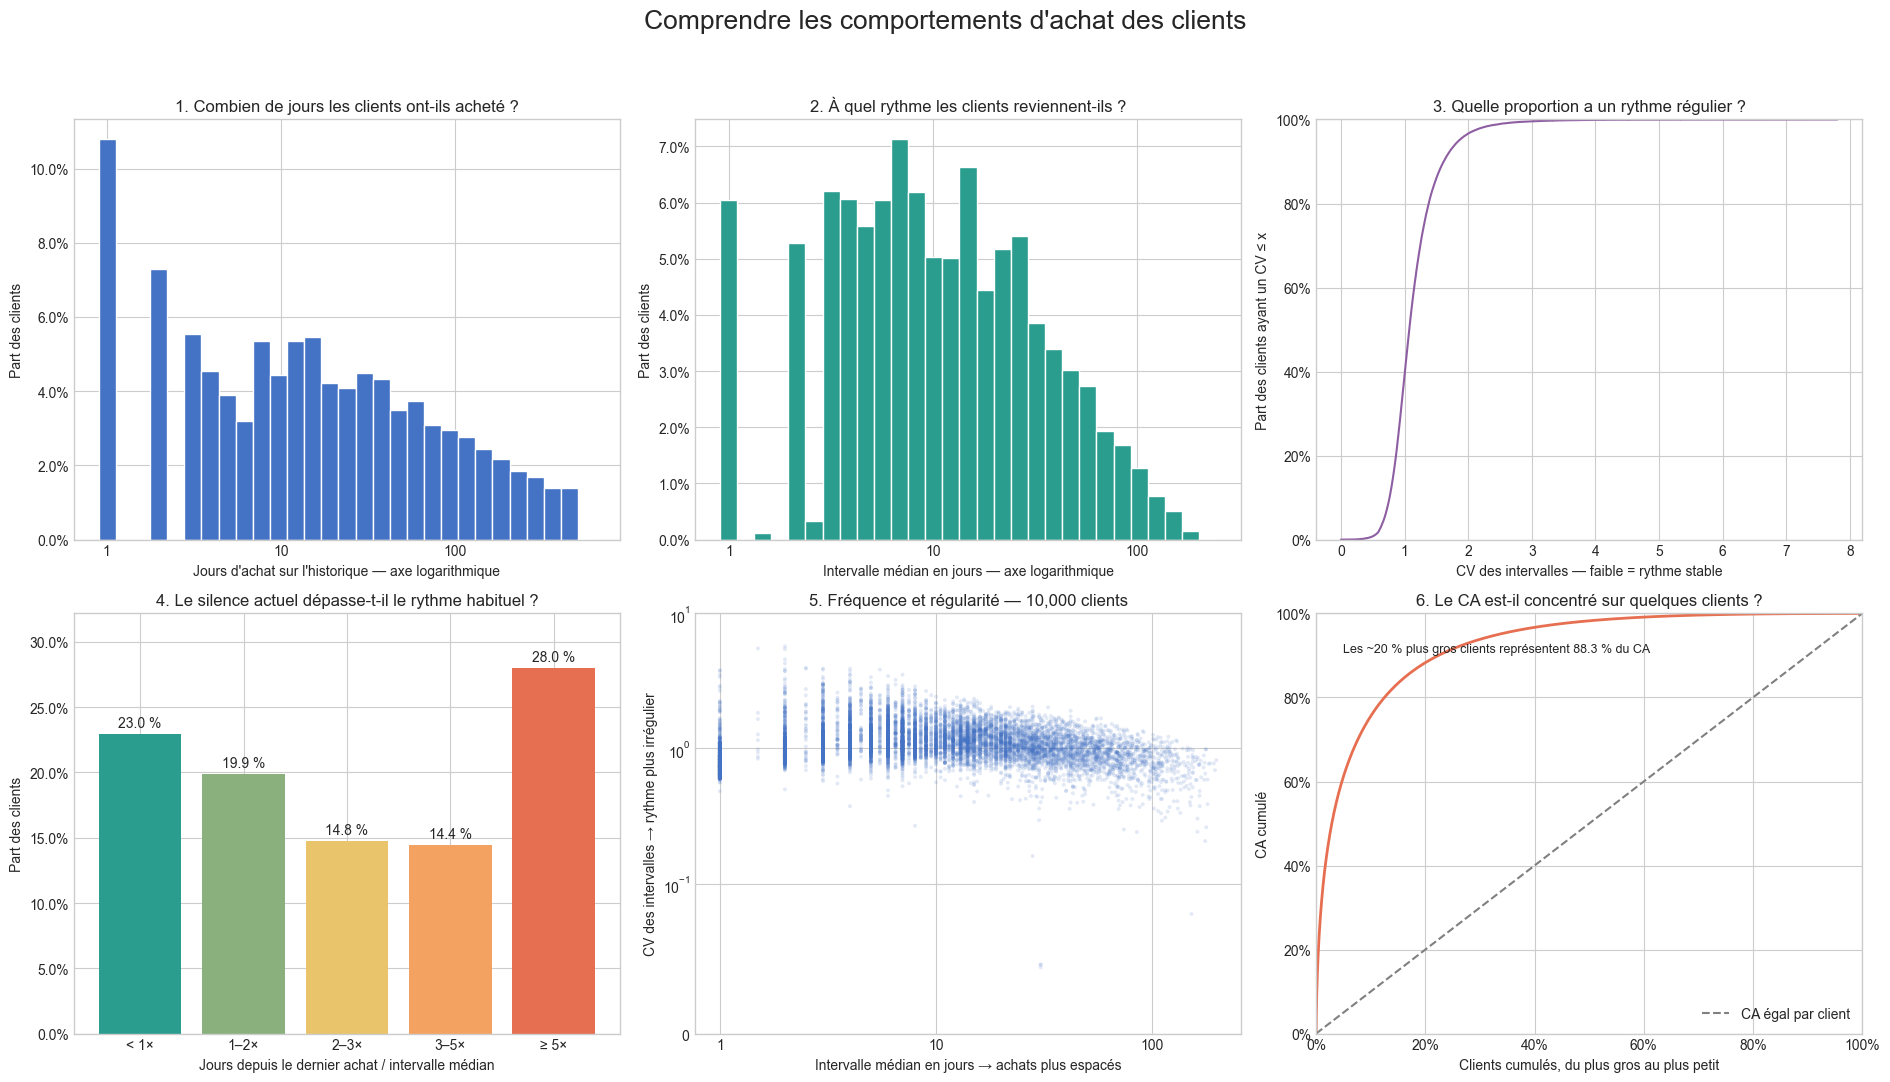

In [8]:
from matplotlib.ticker import PercentFormatter, ScalarFormatter

# profils est le DataFrame Polars obtenu après .collect()
observables = profils.filter(pl.col("anciennete_j") >= 90)

repetes = observables.filter(
    (pl.col("nb_jours_achat") >= 5)
    & (pl.col("intervalle_median_j") > 0)
    & pl.col("cv_intervalles").is_finite()
    & pl.col("retard_relatif").is_finite()
)

print(f"Clients au total : {profils.height:,}")
print(f"Historique ≥ 90 jours : {observables.height:,}")
print(f"Rythme analysable : {repetes.height:,}")

if observables.height == 0 or repetes.height == 0:
    raise ValueError("Pas assez de clients avec les critères retenus.")

plt.style.use("seaborn-v0_8-whitegrid")
fig, axes = plt.subplots(2, 3, figsize=(19, 11))


# Fonction : distribution en % avec classes logarithmiques
def histogramme_log(ax, valeurs, titre, xlabel, couleur):
    x = np.asarray(valeurs, dtype=float)
    x = x[np.isfinite(x) & (x > 0)]

    if len(x) == 0:
        ax.set_title(titre)
        ax.text(0.5, 0.5, "Aucune donnée", ha="center",
                transform=ax.transAxes)
        return

    bins = np.geomspace(
        max(0.5, x.min() * 0.9),
        x.max() * 1.1,
        30,
    )

    ax.hist(
        x,
        bins=bins,
        weights=np.full(len(x), 100 / len(x)),
        color=couleur,
        edgecolor="white",
    )
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.yaxis.set_major_formatter(PercentFormatter(100))
    ax.set(title=titre, xlabel=xlabel, ylabel="Part des clients")


# 1. Nombre de jours d'achat
histogramme_log(
    axes[0, 0],
    observables["nb_jours_achat"].to_numpy(),
    "1. Combien de jours les clients ont-ils acheté ?",
    "Jours d'achat sur l'historique — axe logarithmique",
    "#4472C4",
)


# 2. Intervalle habituel entre deux jours d'achat
histogramme_log(
    axes[0, 1],
    repetes["intervalle_median_j"].to_numpy(),
    "2. À quel rythme les clients reviennent-ils ?",
    "Intervalle médian en jours — axe logarithmique",
    "#2A9D8F",
)


# 3. Régularité : distribution cumulée du CV
cv = np.sort(repetes["cv_intervalles"].to_numpy())
part_cumulee = 100 * np.arange(1, len(cv) + 1) / len(cv)

axes[0, 2].step(cv, part_cumulee, where="post", color="#8E5EA2")
# axes[0, 2].set_xscale("symlog", linthresh=0.1)
axes[0, 2].yaxis.set_major_formatter(PercentFormatter(100))
axes[0, 2].set(
    title="3. Quelle proportion a un rythme régulier ?",
    xlabel="CV des intervalles — faible = rythme stable",
    ylabel="Part des clients ayant un CV ≤ x",
    ylim=(0, 100),
)


# 4. Silence actuel rapporté au rythme habituel
retards = repetes["retard_relatif"].to_numpy()
bornes = [0, 1, 2, 3, 5, np.inf]
effectifs, _ = np.histogram(retards, bins=bornes)
parts = 100 * effectifs / len(retards)

ax = axes[1, 0]
barres = ax.bar(
    ["< 1×", "1–2×", "2–3×", "3–5×", "≥ 5×"],
    parts,
    color=["#2A9D8F", "#8AB17D", "#E9C46A", "#F4A261", "#E76F51"],
)
ax.bar_label(barres, labels=[f"{v:.1f} %" for v in parts], padding=3)
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set(
    title="4. Le silence actuel dépasse-t-il le rythme habituel ?",
    xlabel="Jours depuis le dernier achat / intervalle médian",
    ylabel="Part des clients",
)
ax.margins(y=0.15)


# 5. Fréquence et régularité : échantillon pour garder un graphe léger
echantillon = repetes.sample(
    n=min(10_000, repetes.height),
    seed=42,
)

ax = axes[1, 1]
ax.scatter(
    echantillon["intervalle_median_j"].to_numpy(),
    echantillon["cv_intervalles"].to_numpy(),
    s=8,
    alpha=0.15,
    color="#4472C4",
    edgecolors="none",
)
ax.set_xscale("log")
ax.set_ylim(0, 10)
ax.set_yscale("symlog", linthresh=0.1)
ax.xaxis.set_major_formatter(ScalarFormatter())
ax.set(
    title=f"5. Fréquence et régularité — {echantillon.height:,} clients",
    xlabel="Intervalle médian en jours → achats plus espacés",
    ylabel="CV des intervalles → rythme plus irrégulier",
)


# 6. Concentration du CA — tous les clients avec CA strictement positif
ca = (
    profils
    .filter(pl.col("ca_total").is_finite() & (pl.col("ca_total") > 0))
    .sort("ca_total", descending=True)
    ["ca_total"]
    .to_numpy()
)

ax = axes[1, 2]

if len(ca) > 0:
    part_clients = 100 * np.arange(1, len(ca) + 1) / len(ca)
    part_ca = 100 * np.cumsum(ca) / ca.sum()

    ax.plot(
        np.r_[0, part_clients],
        np.r_[0, part_ca],
        color="#E76F51",
        linewidth=2,
    )
    ax.plot([0, 100], [0, 100], "--", color="grey", label="CA égal par client")

    n_top = max(1, int(np.ceil(0.2 * len(ca))))
    poids_top = 100 * ca[:n_top].sum() / ca.sum()

    ax.text(
        0.05, 0.93,
        f"Les ~20 % plus gros clients représentent {poids_top:.1f} % du CA",
        transform=ax.transAxes,
        va="top",
        fontsize=9,
    )
    ax.legend(loc="lower right")

ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.yaxis.set_major_formatter(PercentFormatter(100))
ax.set(
    title="6. Le CA est-il concentré sur quelques clients ?",
    xlabel="Clients cumulés, du plus gros au plus petit",
    ylabel="CA cumulé",
    xlim=(0, 100),
    ylim=(0, 100),
)

fig.suptitle("Comprendre les comportements d'achat des clients", fontsize=19)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

# Le dataset  est il représentatif du groupe ?

In [11]:
resultat = (
    lf.filter(pl.col("date_order").is_not_null())
    .group_by(pl.col("date_order").dt.year().alias("annee"))
    .agg(
        pl.col("branch_id").drop_nulls().n_unique().alias("nb_branches"),
        pl.col("sales_net").sum().alias("total_sales_net"),
    )
    .sort("annee")
    .collect()
)

display(resultat)

annee,nb_branches,total_sales_net
i32,u32,f64
2022,540,1.2821e9
2023,561,4.6275e9
2024,565,3.4580e9


On nous indique environ 15.5 milliards de revenus, on est plutot vers 3 ou 4 avec les data, donc il faudrait multiplier par un facteur pour obtenir les gains réels de CA en supposant que c'est linéaire. 2024: dataset: 3.45 millards vs 15.50 en vrai: il faut multiplier par 4.49

# Use case 1: Forecast du CHRUM

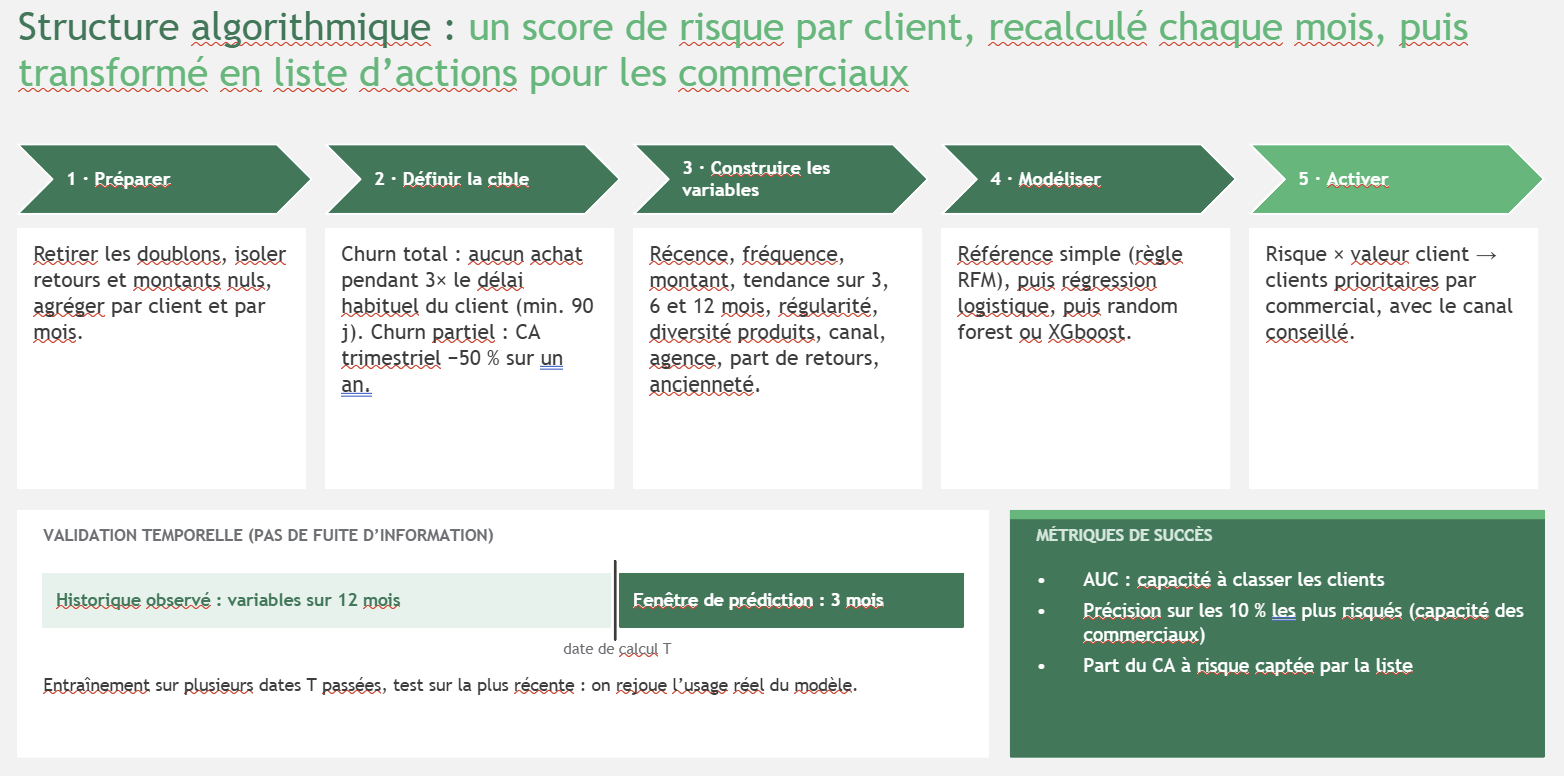

## 1.  Préparation des data d'entrainement

In [14]:
quotidien.describe()

statistic,client_id,date,ca_achats,nb_lignes
str,f64,str,f64,f64
"""count""",7.955289e6,"""7955289""",7.955289e6,7.955289e6
"""null_count""",0.0,"""0""",0.0,0.0
"""mean""",1.1415e6,"""2023-09-21 06:32:00.125441""",1177.526081,7.959398
"""std""",655841.838619,null,4597.771329,12.731304
"""min""",6.0,"""2022-09-22""",-217564.124471,1.0
"""25%""",572235.0,"""2023-03-19""",133.960234,2.0
"""50%""",1.147286e6,"""2023-09-23""",378.02294,4.0
"""75%""",1.710605e6,"""2024-03-21""",1042.4244,9.0
"""max""",2.274517e6,"""2024-09-22""",4.2707e6,3292.0


```markdown
## Étape 1 — Construire la table de churn

La fonction `construire_lf_churn(quotidien)` produit le `LazyFrame` Polars
`lf_churn`, destiné à préparer les données d’entraînement de XGBoost.
La table source `quotidien` contient une ligne par client et par jour
d’achat. Si `date` est une chaîne au format `AAAA-MM-JJ`, la fonction
la convertit en date.

### Éligibilité et échéance

Chaque lundi, un client est éligible s’il a acheté sur **au moins
6 jours distincts** avant la date du score et que son échéance est
encore à venir. L’échéance est calculée avec les achats connus à
cette date.

**Échéance = dernier jour d’achat + 3 × intervalle médian entre deux jours d’achat**

Par exemple, pour un client dont l’intervalle médian est de 14 jours,
l’échéance tombe 42 jours après son dernier achat.

### Cible et variables

- `churn = 0` si le client rachète au plus tard à l’échéance.
- `churn = 1` si l’historique couvre l’échéance et qu’aucun rachat
  n’a eu lieu à temps.
- `churn = null` si l’historique s’arrête avant l’échéance et qu’aucun
  rachat n’a encore été observé.

La table contient notamment le nombre de jours d’achat observés,
l’intervalle médian, la récence et le retard relatif
(`recence_j / intervalle_median_j`). Ces variables sont calculées
uniquement à partir des achats antérieurs au score. Un achat le jour
du score peut entrer dans la cible.

### Résultat sur l’historique complet

La pipeline génère **5 385 447 lignes** pour **111 861 clients**.
Parmi elles, **172 000** ont une cible inconnue et sont à exclure
de l’entraînement.
```

In [17]:
def construire_lf_churn(quotidien: pl.LazyFrame) -> pl.LazyFrame:
    date_achat = pl.col("date")
    if quotidien.collect_schema()["date"] == pl.String:
        date_achat = date_achat.str.to_date(format="%Y-%m-%d")

    achats = (
        quotidien.select("client_id", date_achat.cast(pl.Date), "ca_achats")
        .drop_nulls(subset=["client_id", "date"])
        .unique(subset=["client_id", "date"])
        .with_columns(
            pl.col("date").max().alias("fin_observation"),
            pl.col("date")
            .cum_count()
            .over("client_id", order_by="date")
            .alias("nb_jours_achat"),
            pl.col("date")
            .diff()
            .over("client_id", order_by="date")
            .dt.total_days()
            .alias("intervalle_j"),
            pl.col("date")
            .shift(-1)
            .over("client_id", order_by="date")
            .alias("prochain_achat"),
        )
        .with_columns(
            pl.col("intervalle_j")
            .cumulative_eval(pl.element().median(), min_samples=5)
            .over("client_id", order_by="date")
            .alias("intervalle_median_j"),
            pl.col("ca_achats")
            .cumulative_eval(pl.element().median(), min_samples=1)
            .over("client_id", order_by="date")
            .alias("ca_median_jour_achat")
        )
        .filter(pl.col("nb_jours_achat") > 5)
        .rename({"date": "dernier_achat"})
    )

    return (
        achats.with_columns(
            # Le calcul en heures conserve les demi-journées de la médiane.
            (
                pl.col("dernier_achat").cast(pl.Datetime("us"))
                + pl.duration(
                    hours=(3 * 24 * pl.col("intervalle_median_j")).cast(pl.Int64)
                )
            ).alias("echeance"),
            (
                pl.col("dernier_achat")
                + pl.duration(days=8 - pl.col("dernier_achat").dt.weekday())
            ).alias("premier_lundi"),
        )
        # Un achat le lundi compte dans la cible du jour.
        .with_columns(
            pl.min_horizontal(
                pl.col("prochain_achat"),
                pl.col("echeance").dt.date(),
                pl.col("fin_observation"),
            ).alias("fin_scoring")
        )
        .filter(pl.col("premier_lundi") <= pl.col("fin_scoring"))
        .with_columns(
            pl.date_ranges("premier_lundi", "fin_scoring", interval="1w")
            .alias("date_score")
        )
        .explode("date_score")
        .filter(pl.col("date_score").cast(pl.Datetime("us")) < pl.col("echeance"))
        .with_columns(
            (pl.col("date_score") - pl.col("dernier_achat"))
            .dt.total_days()
            .alias("recence_j"),
            pl.when(pl.col("prochain_achat") <= pl.col("echeance").dt.date())
            .then(0)
            .when(pl.col("echeance").dt.date() <= pl.col("fin_observation"))
            .then(1)
            .otherwise(None)
            .cast(pl.Int8)
            .alias("churn"),
        )
        .with_columns(
            (pl.col("recence_j") / pl.col("intervalle_median_j"))
            .alias("retard_relatif")
        )
        .select(
            "client_id",
            "date_score",
            "dernier_achat",
            "nb_jours_achat",
            "intervalle_median_j",
            "echeance",
            "recence_j",
            "retard_relatif",
            "churn",
            "ca_median_jour_achat"
        )
    )


lf_churn = construire_lf_churn(quotidien)

In [18]:
lf_churn.describe()

statistic,client_id,date_score,dernier_achat,nb_jours_achat,intervalle_median_j,echeance,recence_j,retard_relatif,churn,ca_median_jour_achat
str,f64,str,str,f64,f64,str,f64,f64,f64,f64
"""count""",5.385447e6,"""5385447""","""5385447""",5.385447e6,5.385447e6,"""5385447""",5.385447e6,5.385447e6,5.213447e6,5.385447e6
"""null_count""",0.0,"""0""","""0""",0.0,0.0,"""0""",0.0,0.0,172000.0,0.0
"""mean""",1.1411e6,"""2023-11-11 12:10:07.709777""","""2023-10-28 15:08:07.515855""",45.242847,13.575172,"""2023-12-08 08:32:52.010568""",13.876391,1.149296,0.301492,458.588863
"""std""",656131.104186,null,null,52.904438,16.151642,null,20.047471,0.743131,0.458906,1740.772307
"""min""",6.0,"""2022-10-03""","""2022-10-01""",6.0,1.0,"""2022-10-04 00:00:00""",1.0,0.007576,0.0,-10.212
"""25%""",572045.0,"""2023-06-12""","""2023-06-05""",11.0,4.0,"""2023-07-02 12:00:00""",4.0,0.5,0.0,177.418527
"""50%""",1.145653e6,"""2023-11-20""","""2023-11-05""",23.0,7.0,"""2023-12-16 00:00:00""",6.0,1.0,0.0,293.1419
"""75%""",1.710515e6,"""2024-04-22""","""2024-04-01""",57.0,17.0,"""2024-05-24 12:00:00""",15.0,1.666667,1.0,507.84
"""max""",2.274517e6,"""2024-09-16""","""2024-09-15""",566.0,200.0,"""2026-03-30 00:00:00""",308.0,2.993464,1.0,2.9793e6


In [ ]:
from train_churn import entrainer_churn

resultats = entrainer_churn(lf_churn)

modele = resultats["modele"]
variables = resultats["variables"]

display(resultats["metriques_test"])
display(resultats["couverture_test"])